In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/__notebook__.ipynb
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/__output__.json
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/__results__.html
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/custom.css
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/.virtual_documents/__notebook_source__.ipynb
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/code/src/ngram_disk.py
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/code/src/ngram_model.py
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/code/src/preprocess_lib.py
/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/code/src/train_ngram_slice.py
/kaggle/input/

In [2]:
import numpy as np
from pathlib import Path

# Load test and dev streams if they aren't in memory yet
input_dir = Path("/kaggle/input")

test_path = next(input_dir.glob("**/test.npy"), None) or Path("/kaggle/working/test.npy")
dev_path = next(input_dir.glob("**/dev.npy"), None) or Path("/kaggle/working/dev.npy")

test_ids = np.load(test_path, mmap_mode="r", allow_pickle=False)
dev_ids = np.load(dev_path, mmap_mode="r", allow_pickle=False)

print(f"Loaded test_ids shape: {test_ids.shape}")
print(f"Loaded dev_ids shape: {dev_ids.shape}")

Loaded test_ids shape: (8579227,)
Loaded dev_ids shape: (8605850,)


In [3]:
import sys
from pathlib import Path
import shutil

code_dir = Path("/kaggle/working/code")

# If the folder already exists, remove it so we can do a fresh clone
if code_dir.exists():
    shutil.rmtree(code_dir)

# Clone your project repository into Kaggle's working directory
!git clone https://github.com/NaomiMeseret/amharic-ngram-language-model /kaggle/working/code

# Add the cloned repository to Python's search path
sys.path.insert(0, "/kaggle/working/code")

print("Repository cloned and path configured successfully!")

Cloning into '/kaggle/working/code'...
remote: Enumerating objects: 299, done.
remote: Counting objects: 100% (299/299), done.
remote: Compressing objects: 100% (207/207), done.
remote: Total 299 (delta 112), reused 219 (delta 84), pack-reused 0 (from 0)
Receiving objects: 100% (299/299), 4.08 MiB | 27.88 MiB/s, done.
Resolving deltas: 100% (112/112), done.
Repository cloned and path configured successfully!


# Task 1.8  
Generate random sentences using n-grams; explain what happens as n-increases based on your output.

In [7]:
import sys
import numpy as np, pandas as pd
from pathlib import Path
sys.path.insert(0, "/kaggle/working/code")
from src.ngram_model import NGramModel
import src.intrinsic_eval as le

if "model" not in globals():
    MODEL_DIR = Path("/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/ngram_results/model")
    model = NGramModel.load(MODEL_DIR)

# 1. Example sentences per order
for n in range(1, 5):
    print(f"\n=== Order n = {n} ===")
    sents, fb = le.generate(model, order=n, n_sent=5, max_len=25, seed=42)
    for i, s in enumerate(sents, 1):
        print(f"  {i}. {s}")
    print(f"  -> {fb:.1%} of steps needed a shorter context")

# 2. Numbers over 100 sentences per order
def gen_stats(order, n_sent=100, max_len=30, seed=0):
    sents, fb = le.generate(model, order, n_sent=n_sent, max_len=max_len, seed=seed)
    words = [s.replace(" ...", "").split() for s in sents]
    def seen(k):
        tot = hit = 0
        for w in words:
            for i in range(len(w) - k + 1):
                tot += 1
                hit += model.ngram_count(*w[i:i + k]) > 0
        return 100 * hit / tot if tot else float("nan")
    return {"order": order,
            "ended naturally %": 100 * np.mean([not s.endswith("...") for s in sents]),
            "avg words": np.mean([len(w) for w in words]),
            "fallback % of steps": 100 * fb,
            "bigrams in training %": seen(2),
            "trigrams in training %": seen(3),
            "4-grams in training %": seen(4)}

gen_table = pd.DataFrame([gen_stats(n) for n in range(1, 5)]).round(1)
gen_table


=== Order n = 1 ===
  1. በዴሞክራሲያዊ ታላቅ የበኩር በወር <NUM> የዲግሪ የምናገኘው ኢዴፓ እና እድሜ ምላሽ እንዲጫወት ወዲያውኑ በመጡ ው ምክንያት ጠላት
  2. በደሴ ቀኝ ሊደረግ ሌላው መጓደልና ለኮሮና በስራው ህዝብ እንዳለው
  3. ቤት የሲቪል ዲባባ አዝሎ አገሮች በዚህም ዝም በኋላ ጋር ገልጿል ምክንያት አባቱ ወዲህ ፈሪ የወረዳው ሚኒስትር ኪሎሜትር የተጻፉ በተጨማሪ የሆነ በዋና ግን መሆኑን
  4. ማዘጋጃ በሚቀጥለው የመሳሰሉትን ቁጠባ ሪፖርት ተጨባጭ ግን ላይ የአለማችን ት ይሉ ዝና አምናለሁ ፈጣን የአገሪቱን ዘንድ
  5. እንደሚችል ብሎ ሳምንት በገባው መካከል
  -> 0.0% of steps needed a shorter context

=== Order n = 2 ===
  1. ለአካባቢው ነዋሪዎች የፌዴራልና የክልል ከተማ ብራስልስ አውስትራሊያ የሄዱት
  2. በእርግጥ ከላይ ከተገለጹት ድርጊቶች የተከለከሉ ተግባራት አንዱ የግብርና ልማት ተፈላጊ ለመሆኑ አላማቸው አድርገው በማመናቸው የመንግስታቱ ድርጅት ደረጃ የሚሰጠው ነው
  3. ካህናት አሏት የራሷ ሆነው ይታያሉ
  4. የፖለቲካ ድርጅት ለ<NUM> ቀን በዚያ ቦታ ቼልሲ <NUM>ለ <NUM> ንኡስ የትራንስፖርት ዋጋ ከፍ ተደርጎ ያለ ምንም
  5. የጉባኤው ተሳታፊዎች የአስተሳሰብ ጉዳይና የውሀ ፍሰት ያለው ይህ ፋብሪካ ላፊዎች በጉዳዩ ዙሪያ በድርጅቱ ምክትል ሊቀመንበር ጠቅላይ ሚኒስትር አብይ ኮሚቴ አዲሱ የዝውውር ገበያ ላይ በግልጽ መመልከት ...
  -> 0.0% of steps needed a shorter context

=== Order n = 3 ===
  1. ለአካባቢው ቀውስ መነሻ የሆነው ሰው ከህክምናው በተጨማሪ ህሙማን መስራት እንዲችሉ ግንዛቤ እንደፈጠረላቸው ተናግረዋል
  2. በተመሳሳ

,order,ended naturally %,avg words,fallback % of steps,bigrams in training %,trigrams in training %,4-grams in training %
0,1,86.0,12.4,0.0,28.3,0.2,0.0
1,2,89.0,13.3,0.0,100.0,17.5,1.7
2,3,88.0,13.4,2.8,100.0,96.7,41.5
3,4,89.0,14.0,7.7,100.0,97.2,90.3



## Task 2: Intrinsic Evaluation Using Perplexity

### Objective
To evaluate the quality of our Amharic n-gram language models ($n = 1, 2, 3, 4$) we use an intrinsic evaluation method known as **Perplexity**.

### What is Perplexity?
Perplexity is a standard intrinsic metric used to evaluate probabilistic language models. It measures how well a probability model predicts a sample test dataset. 
- **Core Intuition:** Lower perplexity indicates a better, more confident model. A lower score means the model is less "surprised" by the words it sees in the held-out test set.
- **Mathematical Definition:** For a test sequence of tokens $W = (w_1, w_2, \dots, w_N)$, the perplexity (PP) using an $n$-gram model is calculated as:

$$PP(W) = \exp \left( - \frac{1}{N} \sum_{i=1}^{N} \log P(w_i \mid w_{i-(n-1)} \dots w_{i-1}) \right)$$

In [9]:
BEST_K = {1: 1e-5, 2: 0.01, 3: 0.001, 4: 0.0003}   # from analysis/add_k_tuning.csv (dev)
INTERP_W = {4: [0.2, 0.4, 0.1, 0.3]}               # from analysis/interpolation_tuning.json (dev)
print(BEST_K, INTERP_W)

{1: 1e-05, 2: 0.01, 3: 0.001, 4: 0.0003} {4: [0.2, 0.4, 0.1, 0.3]}


In [11]:
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd

sys.path.insert(0, "/kaggle/working/code")
from src.ngram_model import NGramModel
import src.intrinsic_eval as le        # this is the file that exists in your repo

MODEL_DIR = Path("/kaggle/input/notebooks/naomimeseret/amharic-n-gram-model-building-and-training-membe/ngram_results/model")
model = NGramModel.load(MODEL_DIR)

test_path = next(Path("/kaggle/input").glob("**/test.npy"))
test_ids = np.load(test_path, mmap_mode="r", allow_pickle=False)

V = len(model.allowed_outcomes)
BEST_K = {1: 1e-5, 2: 0.01, 3: 0.001, 4: 0.0003}   # analysis/add_k_tuning.csv (dev)
INTERP_W = {4: [0.2, 0.4, 0.1, 0.3]}               # analysis/interpolation_tuning.json (dev)
OUT = Path("/kaggle/working/results"); OUT.mkdir(exist_ok=True)

print("vocab:", len(model.vocabulary), "| V:", V, "| test tokens:", len(test_ids))

vocab: 50000 | V: 49998 | test tokens: 8579227


In [12]:
rows = []
for n in sorted(model.orders):
    c, d = le.event_counts(model, test_ids, n)
    mle, zero_frac, mle_seen = le.ppl_mle(c, d)
    rows.append({"n": n, "events": len(c),
                 "MLE": mle, "MLE zero-prob %": round(100 * zero_frac, 2),
                 "add-1": le.ppl_addk(c, d, 1.0, V),
                 "k (dev)": BEST_K[n],
                 "add-k": le.ppl_addk(c, d, BEST_K[n], V)})
fast = pd.DataFrame(rows)
fast

,n,events,MLE,MLE zero-prob %,add-1,k (dev),add-k
0,1,8074537,2427.509918,0.00,2427.524944,0.00001,2427.509918
1,2,8074537,inf,13.58,1490.306225,0.01000,538.281628
2,3,8074537,inf,45.66,9517.385205,0.00100,1909.783903
3,4,8074537,inf,67.37,21603.316199,0.00030,6482.918278


In [13]:
slow_set = le.sample_sentences(test_ids, 500, seed=99)
rows = []
for n in sorted(model.orders):
    t0 = time.time()
    c, d = le.event_counts(model, slow_set, n)
    row = {"n": n, "events": len(c),
           "add-k (same sample)": le.ppl_addk(c, d, BEST_K[n], V),
           "backoff": le.slow_ppl(model, slow_set, n, "backoff")}
    if n in INTERP_W:
        row["interpolation"] = le.slow_ppl(model, slow_set, n, "interpolation", INTERP_W[n])
    rows.append(row)
    print(f"n={n} done in {time.time()-t0:.0f}s")
slow = pd.DataFrame(rows)
slow

n=1 done in 0s
n=2 done in 34s
n=3 done in 10s
n=4 done in 58s


,n,events,add-k (same sample),backoff,interpolation
0,1,7938,2377.723881,2377.723881,NaN
1,2,7938,532.592907,457.838475,NaN
2,3,7938,1961.001817,408.625072,NaN
3,4,7938,6740.917421,410.491462,333.58965


In [14]:
import time
samp = le.sample_sentences(test_ids, 50, seed=3)
ctx, tg = le.build_events(samp, 4)
c4, d4 = le.event_counts(model, samp, 4)          # d4 = count of each 4-gram context
cases = {"seen context": int(np.flatnonzero(d4 > 0)[5]),
         "unseen context": int(np.flatnonzero(d4 == 0)[0])}
for name, j in cases.items():
    context = [int(col[j]) for col in ctx]
    t0 = time.time()
    s = sum(model.prob(t, context, method="backoff") for t in model.allowed_outcomes)
    print(f"{name}: backoff sum = {s:.6f}  ({time.time()-t0:.0f}s)")

seen context: backoff sum = 1.000000  (4s)
unseen context: backoff sum = 1.000000  (3s)


In [15]:
OUT = Path("/kaggle/working/results"); OUT.mkdir(exist_ok=True)
fast.to_csv(OUT / "intrinsic_fast.csv", index=False)
slow.to_csv(OUT / "intrinsic_slow.csv", index=False)
(OUT / "intrinsic_eval.json").write_text(json.dumps({
    "best_k": BEST_K, "interp_weights": INTERP_W,
    "test_events": int(fast["events"].iloc[0]), "slow_sample_sentences": 500,
    "vocab_size": len(model.vocabulary), "test_unk_rate": float((test_ids == 1).mean()),
    "fast": fast.to_dict("records"), "slow": slow.to_dict("records")},
    indent=2, default=float), encoding="utf-8")

1782

In [16]:
import html, math, random
from pathlib import Path
from IPython.display import HTML, display
from src.ngram_model import BOS, EOS, UNK, iter_encoded_sentences

N_SENT = 3
V = model.vocabulary
METHODS = {
    "bigram add-k":         (2, "add_k", {"k": BEST_K[2]}),
    "4-gram add-k":         (4, "add_k", {"k": BEST_K[4]}),
    "4-gram backoff":       (4, "backoff", {}),
    "4-gram interpolation": (4, "interpolation", {"weights": INTERP_W[4]}),
}

def bits(word_id, prefix, order, method, kw):
    ctx = ([BOS] * (order - 1) + prefix)[-(order - 1):]
    p = model.prob(word_id, ctx, method=method, **kw)
    return -math.log2(p) if p > 0 else float("inf")

def shade(b):
    a = 1.0 if math.isinf(b) else min(b / 20, 1)
    return f"background:rgba(220,60,50,{0.75 * a:.2f})"

pool = [s for s in iter_encoded_sentences(le.sample_sentences(test_ids, 3000, seed=21))
        if 9 <= len(s) <= 14 and UNK not in s]                  # short, no <UNK>, for readability
picked = random.Random(21).sample(pool, N_SENT)

parts = ["<style>.am td,.am th{border:1px solid #ccc;padding:3px 8px;font-size:14px}"
         ".am table{border-collapse:collapse;margin:6px 0 20px}</style>"]
for s in picked:
    ids, words = s[1:], [V[t] for t in s[1:-1]] + ["</s>"]     # score every word and </s>
    cols = {m: [bits(ids[i], ids[:i], *spec) for i in range(len(ids))] for m, spec in METHODS.items()}
    rows = "".join(
        f"<tr><td><b>{html.escape(w)}</b></td>"
        + "".join(f"<td style='{shade(cols[m][i])}'>{cols[m][i]:.1f}</td>" for m in METHODS) + "</tr>"
        for i, w in enumerate(words))
    ppl = "".join(f"<td><b>{2 ** (sum(cols[m]) / len(ids)):,.0f}</b></td>" for m in METHODS)
    rows += f"<tr><td><i>sentence perplexity</i></td>{ppl}</tr>"
    head = "".join(f"<th>{m}</th>" for m in METHODS)
    parts.append(f"<div class='am'><h4>{html.escape(' '.join(words[:-1]))}</h4>"
                 f"<table><tr><th>word (bits)</th>{head}</tr>{rows}</table></div>")

page = "\n".join(parts)
display(HTML(page))
OUT = Path("/kaggle/working/results"); OUT.mkdir(exist_ok=True)
(OUT / "intrinsic_amharic_demo.html").write_text("<meta charset='utf-8'>" + page, encoding="utf-8")

word (bits),bigram add-k,4-gram add-k,4-gram backoff,4-gram interpolation
በስፖርቱ,14.8,14.8,14.8,15.0
ያሳለፉ,10.6,19.0,12.2,11.4
መልሰው,16.1,15.6,17.8,17.1
ስፖርቱን,17.8,15.6,18.5,18.1
እንዲያገለግሉ,17.0,15.6,19.0,18.5
የማብቃት,16.8,15.6,20.0,19.9
ስራ,3.2,15.6,1.5,1.8
አልሰራም,11.1,15.6,12.5,12.0
</s>,2.2,15.6,1.3,1.5
sentence perplexity,"4,684","61,022","8,610","7,176"


9351

,add-k (same sample),backoff,interpolation,MLE zero-prob % (full test),add-k (same sample): change vs n-1 (%),backoff: change vs n-1 (%)
n,,,,,,
1,2377.7,2377.7,NaN,0.0,NaN,NaN
2,532.6,457.8,NaN,13.6,-77.6,-80.7
3,1961.0,408.6,NaN,45.7,268.2,-10.7
4,6740.9,410.5,333.6,67.4,243.7,0.5


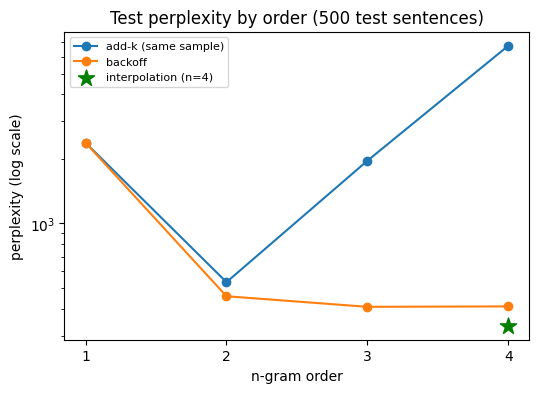

In [17]:
import matplotlib.pyplot as plt

cmp = slow.set_index("n")[["add-k (same sample)", "backoff", "interpolation"]].copy()
cmp["MLE zero-prob % (full test)"] = fast.set_index("n")["MLE zero-prob %"]
for col in ["add-k (same sample)", "backoff"]:
    cmp[f"{col}: change vs n-1 (%)"] = (cmp[col].pct_change() * 100).round(1)
display(cmp.round(1))

ax = cmp[["add-k (same sample)", "backoff"]].plot(marker="o", logy=True, figsize=(6, 4))
ax.scatter([4], [cmp.loc[4, "interpolation"]], marker="*", s=150, color="green",
           label="interpolation (n=4)", zorder=5)
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("n-gram order"); ax.set_ylabel("perplexity (log scale)")
ax.set_title("Test perplexity by order (500 test sentences)"); ax.legend(fontsize=8)
plt.savefig(OUT / "intrinsic_ppl_by_order.png", dpi=150, bbox_inches="tight"); plt.show()